# Homework 4: Time Series Classification
**Name:** Vishnu Gamini  
**GitHub Username:** vishnugamini  
**USC ID:** 6350365744  
**Course:** DSCI 552

In [1]:
from pathlib import Path
import re
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from scipy.special import expit
from scipy.stats import norm
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, MaxAbsScaler, label_binarize
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, roc_auc_score, roc_curve, auc)
from threadpoolctl import threadpool_limits
from IPython.display import display

thread_limits = threadpool_limits(limits=1)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_rows", 50)
pd.set_option("display.float_format", lambda x: f"{x:.5f}")
root = Path("..") if Path("../data/AReM").is_dir() else Path(".")
results_dir = root / "data" / "results"
results_dir.mkdir(parents=True, exist_ok=True)
activities = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
series_names = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
stats = ["min", "max", "mean", "median", "std", "q1", "q3"]
fit_warnings = []
def fit_model(model, X, y):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(X, y)
    fit_warnings.extend(str(w.message) for w in caught if issubclass(w.category, ConvergenceWarning))
    return model

## Data preparation

The Homework 3 cleaning and split are retained: spaces and trailing commas are
handled while parsing, and the absent 13,500 ms reading in `sitting/dataset8.csv`
is interpolated between adjacent readings. There are 69 training and 19 test
recordings. Bending1 and bending2 are combined for binary classification
(bending = 1, other = 0), and remain separate in the seven-class analysis.

For each segmentation level $l$, each of the six series is divided into $l$
consecutive, approximately equal parts. Seven statistics per part give $42l$
features. The number of recordings stays fixed. Standard deviations use
`ddof=1`; quartiles use linear interpolation.

In [2]:
recordings, rows = [], []
for activity in activities:
    paths = sorted((root / "data/AReM" / activity).glob("dataset*.csv"),
                   key=lambda p: int(p.stem.removeprefix("dataset")))
    for path in paths:
        records = []
        for line in path.read_text().splitlines():
            line = line.strip()
            if line and not line.startswith("#"):
                fields = re.split(r"[,\s]+", line.rstrip(","))
                assert len(fields) == 7
                records.append([float(x) for x in fields])
        df = pd.DataFrame(records, columns=["time"] + series_names).set_index("time")
        assert df.index.is_unique and df.index.is_monotonic_increasing
        missing = sorted(set(range(0, 120000, 250)) - set(df.index))
        if missing:
            assert (activity, path.name, missing) == ("sitting", "dataset8.csv", [13500])
        df = df.reindex(range(0, 120000, 250)).interpolate(method="index", limit_area="inside")
        assert df.shape == (480, 6) and np.isfinite(df.to_numpy()).all()
        recordings.append(df.to_numpy())
        number = int(path.stem.removeprefix("dataset"))
        limit = 2 if activity.startswith("bending") else 3
        rows.append({"instance": len(rows) + 1, "activity": activity, "dataset": number,
                     "split": "test" if number <= limit else "train"})
manifest = pd.DataFrame(rows).set_index("instance")
train_mask = manifest["split"].eq("train").to_numpy()
test_mask = ~train_mask
y_binary = manifest["activity"].str.startswith("bending").astype(int).to_numpy()
y_train, y_test = y_binary[train_mask], y_binary[test_mask]
y_multi = manifest["activity"].to_numpy()
ym_train, ym_test = y_multi[train_mask], y_multi[test_mask]
assert len(recordings) == 88 and (sum(train_mask), sum(test_mask)) == (69, 19)
display(pd.crosstab(manifest.activity, manifest.split).reindex(activities)[["train", "test"]])

def segmented_features(l):
    columns = [f"{stat}_s{s + 1}_part{part + 1}"
               for part in range(l) for s in range(6) for stat in stats]
    output = []
    for recording in recordings:
        row = []
        for segment in np.array_split(recording, l, axis=0):
            for s in range(6):
                x = segment[:, s]
                row.extend([x.min(), x.max(), x.mean(), np.median(x),
                            x.std(ddof=1), *np.quantile(x, [.25, .75])])
        output.append(row)
    frame = pd.DataFrame(output, index=manifest.index, columns=columns)
    assert frame.shape == (88, 42*l) and np.isfinite(frame.to_numpy()).all()
    return frame

features = {l: segmented_features(l) for l in range(1, 21)}
manifest.join(features[1]).to_csv(results_dir / "features_l1.csv")
binary_folds = list(StratifiedKFold(5, shuffle=True, random_state=42).split(np.zeros(len(y_train)), y_train))
multiclass_folds = list(StratifiedKFold(4, shuffle=True, random_state=42).split(np.zeros(len(ym_train)), ym_train))

split,train,test
activity,,
bending1,5,2
bending2,4,2
cycling,12,3
lying,12,3
sitting,12,3
standing,12,3
walking,12,3


## 2(a)(i). Scatterplots without segmentation

The three statistics selected in Homework 3 are **mean, standard deviation,
and maximum**. Their pairwise scatterplots for series 1, 2, and 6 are shown
below using training recordings. Blue denotes other activities; red denotes bending.

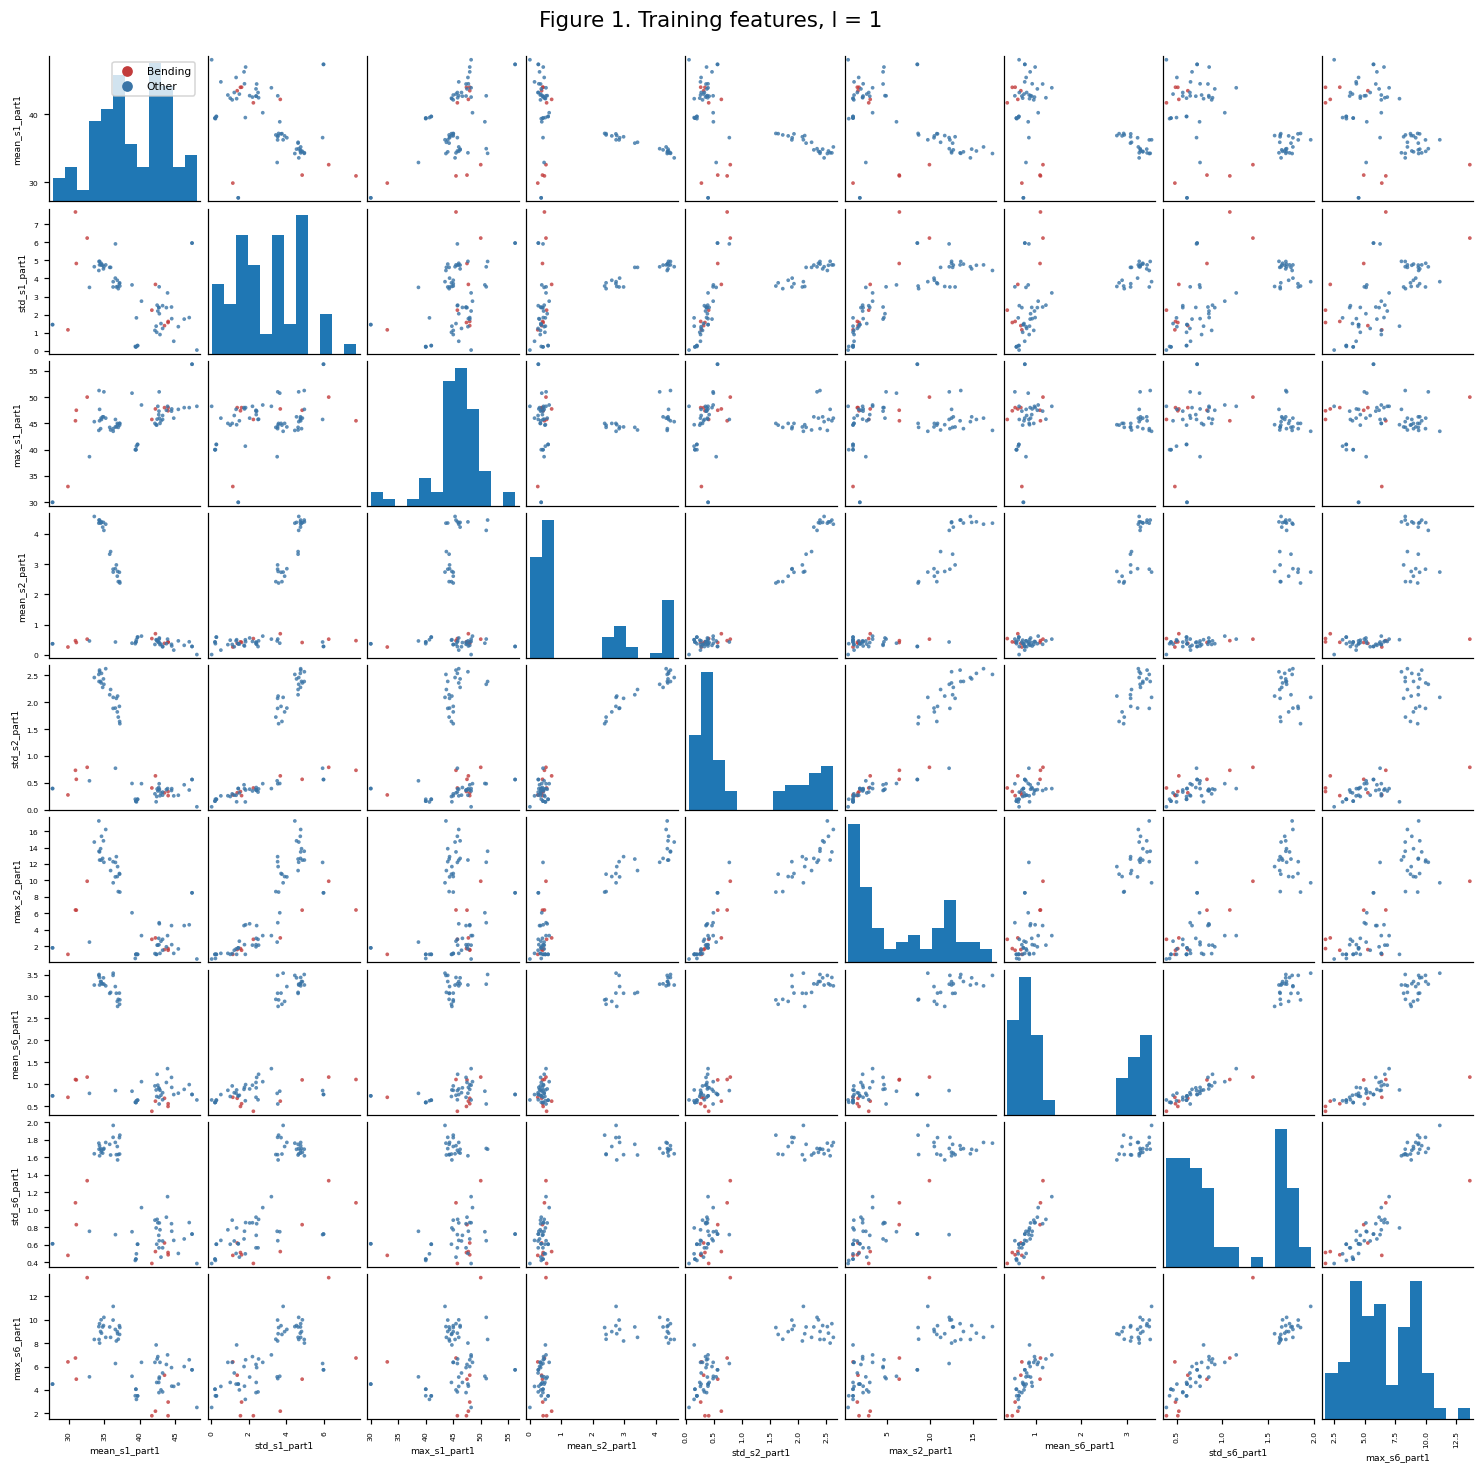

In [3]:
def scatter_matrix(frame, columns, title, size):
    selected = frame.loc[manifest["split"].eq("train"), columns].copy()
    colors = np.where(y_train == 1, "#c23b3b", "#3974a6")
    axes = pd.plotting.scatter_matrix(selected, figsize=size, diagonal="hist",
                                     c=colors, alpha=.8, s=24, hist_kwds={"bins": 12})
    for ax in axes.flat:
        ax.tick_params(labelsize=5)
        ax.xaxis.label.set_size(6)
        ax.yaxis.label.set_size(6)
    axes[0, 0].scatter([], [], c="#c23b3b", label="Bending")
    axes[0, 0].scatter([], [], c="#3974a6", label="Other")
    axes[0, 0].legend(loc="upper right", fontsize=7)
    plt.subplots_adjust(left=.07, right=.995, bottom=.08, top=.965, hspace=.05, wspace=.05)
    plt.suptitle(title, y=.995, fontsize=14)
    plt.show()

scatter_columns = [f"{stat}_s{s}_part1" for s in [1, 2, 6] for stat in ["mean", "std", "max"]]
scatter_matrix(features[1], scatter_columns, "Figure 1. Training features, l = 1", (14, 14))

## 2(a)(ii). Scatterplots after splitting each series in two

Each half contains 240 readings, giving 12 series and 84 total extracted
features. The same three statistics from both halves of original series
1, 2, and 6 give the 18 variables in the following scatterplot matrix.

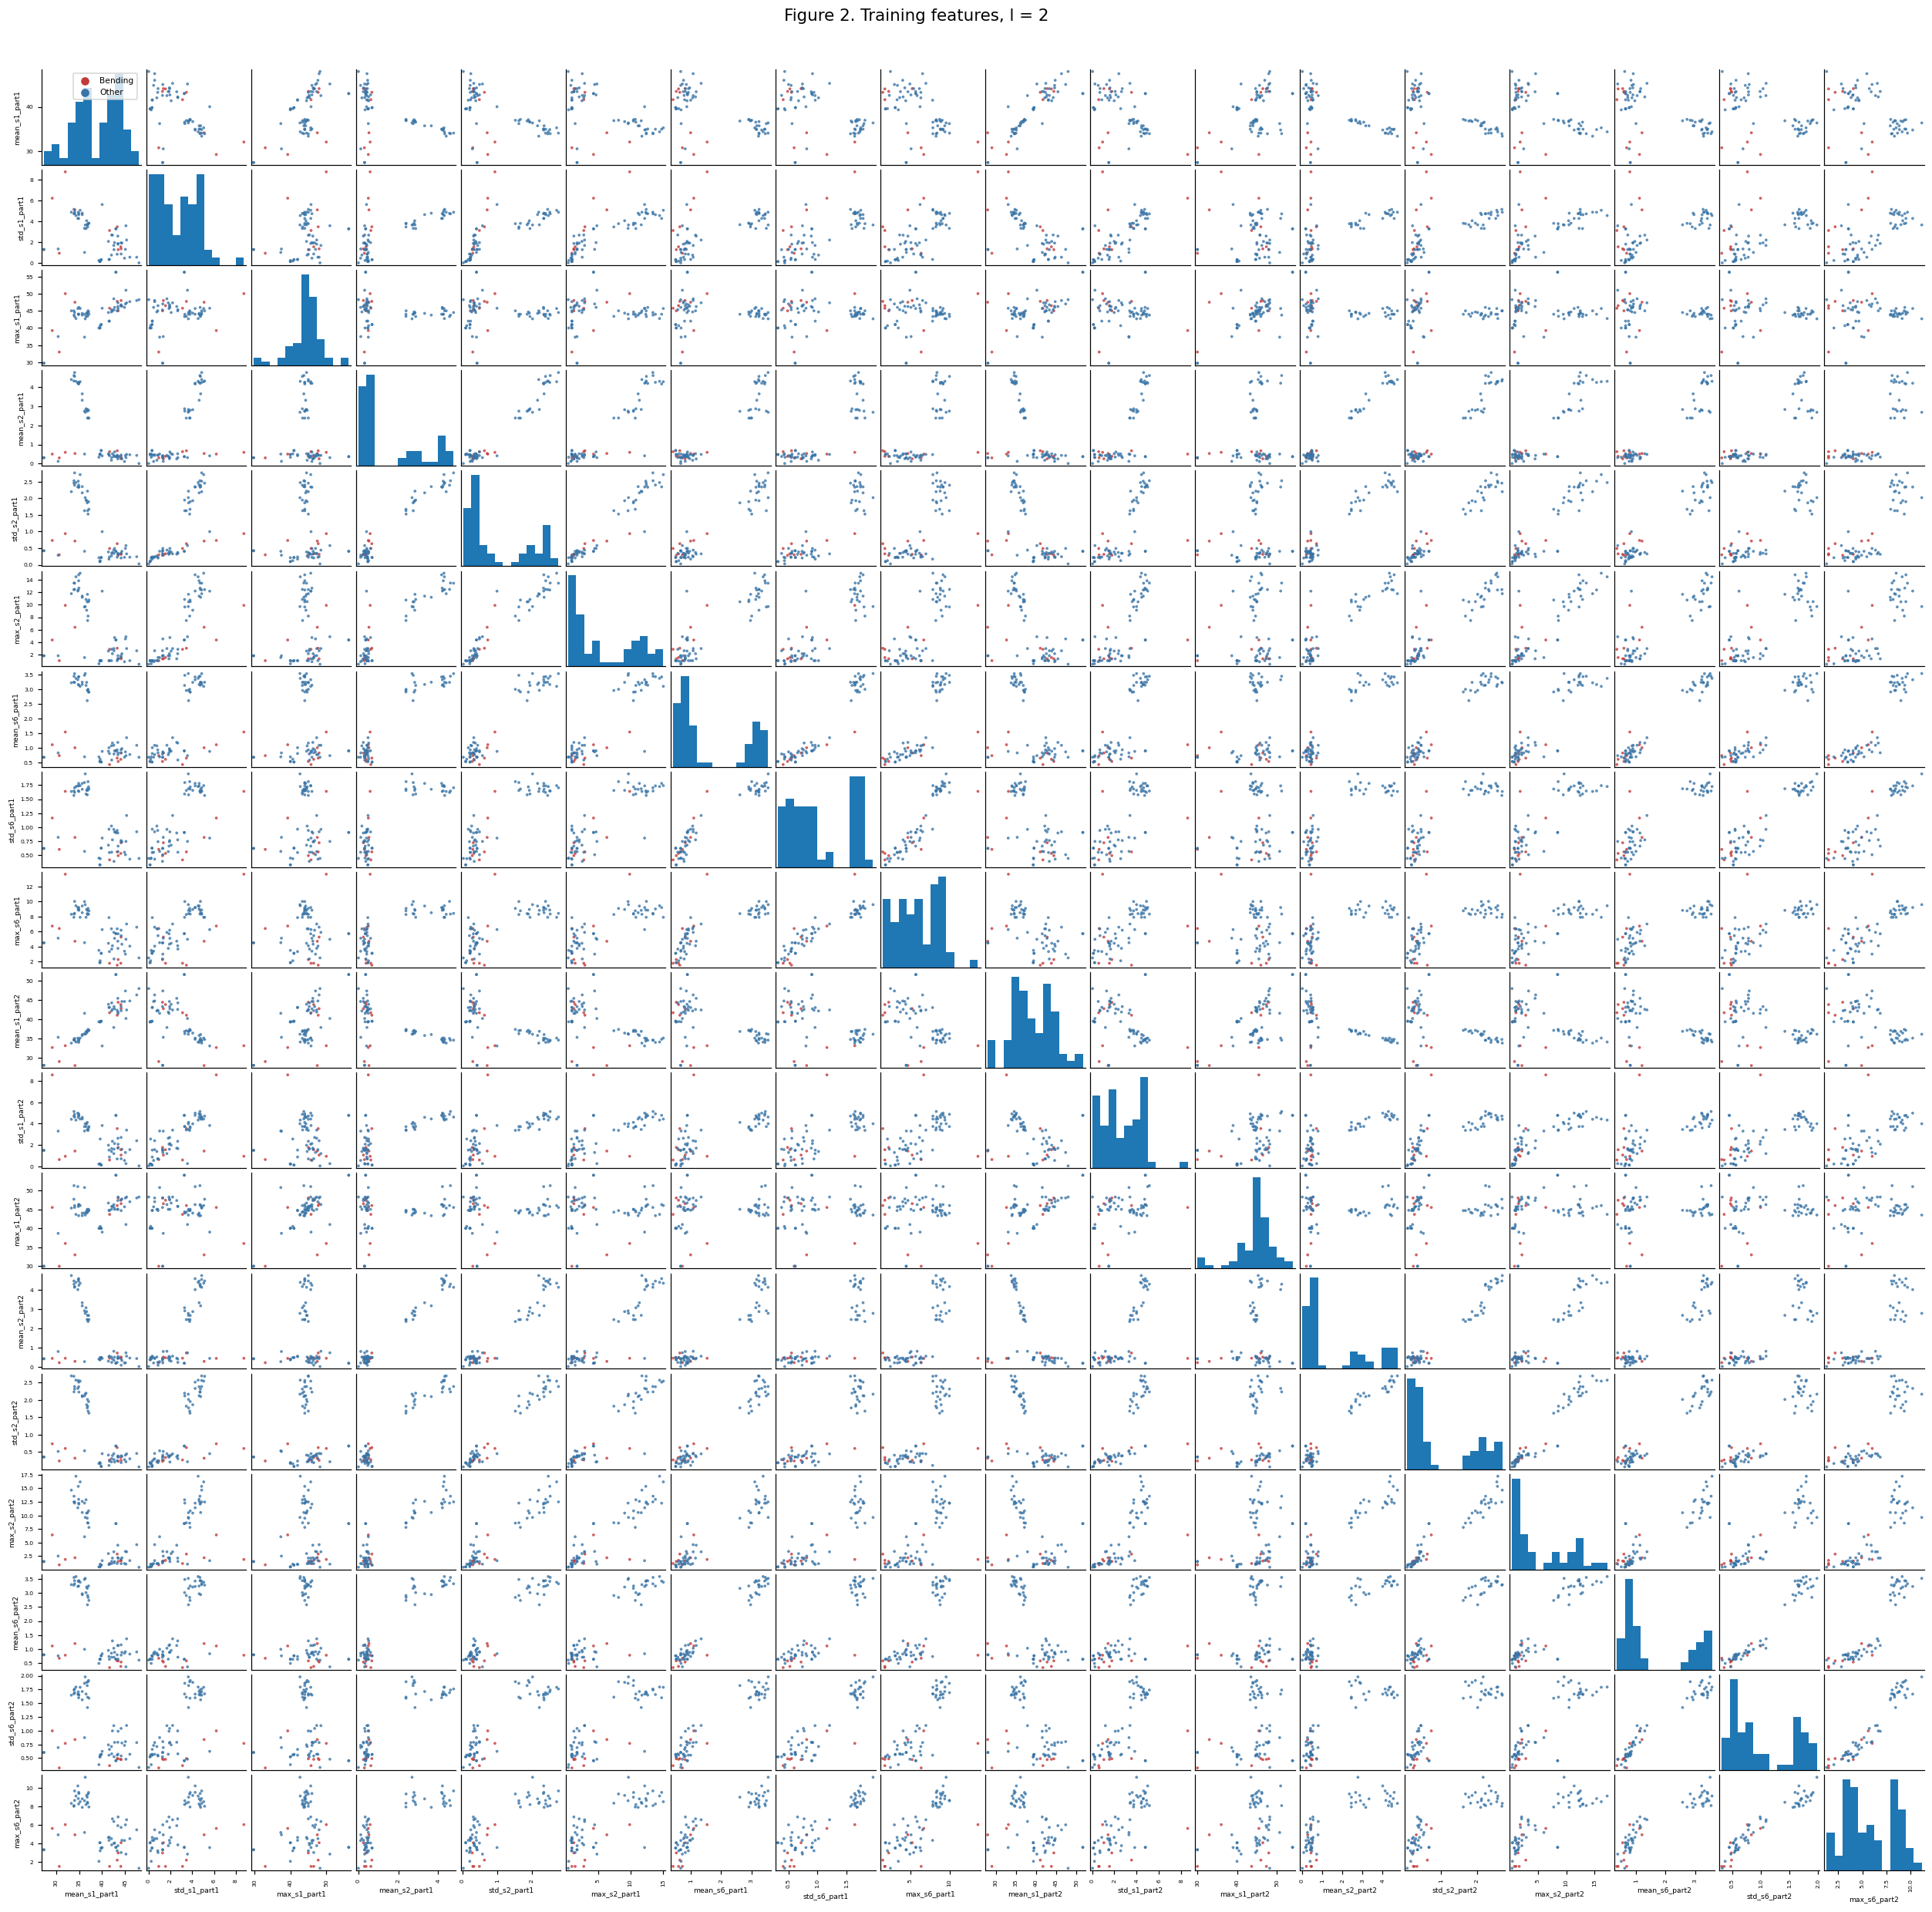

In [4]:
split_columns = [f"{stat}_s{s}_part{part}" for part in [1, 2]
                 for s in [1, 2, 6] for stat in ["mean", "std", "max"]]
scatter_matrix(features[2], split_columns, "Figure 2. Training features, l = 2", (24, 24))

Splitting exposes differences between the beginning and end of a recording.
The broad activity-level structure remains, and many half-recording features
are correlated with their full-recording counterparts. Some bending and other
recordings still overlap in individual projections. The plots alone do not
establish that segmentation improves prediction; cross-validation provides
that comparison.

## 2(a)(iii). Segmentation and recursive feature elimination

Five stratified folds preserve the bending/other proportions as closely as
possible. Each validation fold has one or two bending recordings. Entire
recordings, rather than segments, are assigned to folds.

The search uses $l=1,\ldots,20$ and $p\in\{1,2,3,5,10,20,40\}$.
Within each fold, standardization and recursive feature elimination are fitted
on the fold's training recordings only, then applied to its validation recordings.
RFE removes 20% of the original feature count at each step until $p$ remain.
A large budget $C=10^6$ makes the L2 penalty negligible and stabilizes numerical
optimization. Selection uses mean validation accuracy, with ties resolved by
smaller $p$, then smaller $l$. Results are optimal within this stated grid.

Selecting features or fitting the scaler before splitting into folds would
leak validation information and produce optimistic scores. The 19 test
recordings are excluded from every model-selection decision. The best
cross-validation score is a tuning estimate, not an independent estimate of
the selected model's performance.

In [5]:
def logistic(C=1e6, penalty="l2", solver="liblinear"):
    return LogisticRegression(C=C, penalty=penalty, solver=solver,
                              max_iter=5000, tol=1e-6, random_state=42)

p_grid = [1, 2, 3, 5, 10, 20, 40]
rfe_rows = []
for l in range(1, 21):
    X = features[l].to_numpy()[train_mask]
    scores = {p: [] for p in p_grid}
    for fold_train, fold_valid in binary_folds:
        scaler = StandardScaler().fit(X[fold_train])
        Xt, Xv = scaler.transform(X[fold_train]), scaler.transform(X[fold_valid])
        for p in p_grid:
            selector = RFE(logistic(), n_features_to_select=p, step=.2)
            fit_model(selector, Xt, y_train[fold_train])
            scores[p].append(accuracy_score(y_train[fold_valid], selector.predict(Xv)))
    for p, fold_scores in scores.items():
        rfe_rows.append({"l": l, "p": p, "cv_accuracy": np.mean(fold_scores),
                         **{f"fold_{i+1}": score for i, score in enumerate(fold_scores)}})
rfe_cv = pd.DataFrame(rfe_rows)
rfe_best = rfe_cv.sort_values(["cv_accuracy", "p", "l"], ascending=[False, True, True]).iloc[0]
best_l, best_p = int(rfe_best.l), int(rfe_best.p)
display(rfe_cv.sort_values(["cv_accuracy", "p", "l"], ascending=[False, True, True]).head(15))
display(rfe_cv.loc[rfe_cv.groupby("l").cv_accuracy.idxmax(), ["l", "p", "cv_accuracy"]])
rfe_cv.to_csv(results_dir / "binary_rfe_cv.csv", index=False)

X = features[best_l].to_numpy()
rfe_scaler = StandardScaler().fit(X[train_mask])
Z_train, Z_test = rfe_scaler.transform(X[train_mask]), rfe_scaler.transform(X[test_mask])
rfe_model = fit_model(RFE(logistic(), n_features_to_select=best_p, step=.2), Z_train, y_train)
chosen = features[best_l].columns[rfe_model.support_].tolist()
display(pd.DataFrame({"selected_feature": chosen}))

,l,p,cv_accuracy,fold_1,fold_2,fold_3,fold_4,fold_5
16,3,3,0.98571,1.00000,1.00000,0.92857,1.00000,1.00000
15,3,2,0.97143,0.92857,1.00000,0.92857,1.00000,1.00000
2,1,3,0.97143,1.00000,1.00000,0.85714,1.00000,1.00000
4,1,10,0.97143,1.00000,0.92857,0.92857,1.00000,1.00000
5,1,20,0.97143,1.00000,0.92857,0.92857,1.00000,1.00000
6,1,40,0.97143,1.00000,0.92857,0.92857,1.00000,1.00000
14,3,1,0.95714,1.00000,1.00000,0.92857,0.85714,1.00000
39,6,10,0.95714,1.00000,0.92857,1.00000,0.85714,1.00000
139,20,40,0.95714,1.00000,0.92857,1.00000,0.85714,1.00000
3,1,5,0.95714,1.00000,0.92857,0.92857,0.92857,1.00000


,l,p,cv_accuracy
2,1,3,0.97143
10,2,5,0.95714
16,3,3,0.98571
26,4,20,0.94286
34,5,40,0.92747
39,6,10,0.95714
43,7,2,0.91319
52,8,5,0.94176
61,9,20,0.92857
67,10,10,0.95714


,selected_feature
0,max_s5_part1
1,min_s5_part3
2,std_s6_part3


## 2(a)(iv). Training performance and logistic coefficients

The selected model has **l = 3 and p = 3**, with mean validation accuracy
**98.57%**. It retains `max_s5_part1`, `min_s5_part3`, and `std_s6_part3`.
Its training accuracy is **98.55%** and training AUC is **0.9963**.

Rows of each confusion matrix are true classes; columns are predicted classes.
The positive class for binary ROC and AUC is bending. A threshold of 0.5 is used.

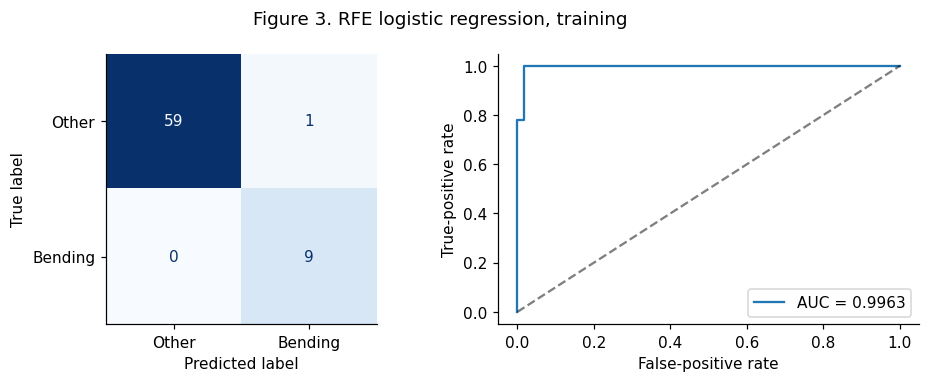

,accuracy,balanced_accuracy,auc
model,,,
RFE train,0.98551,0.99167,0.99630


,coefficient_standardized,standard_error,p_value
term,,,
Intercept,-8.41882,9.94605,0.39730
max_s5_part1,5.73352,6.12092,0.34891
min_s5_part3,3.66212,7.04598,0.60324
std_s6_part3,-1.78897,3.30334,0.58812


complete_separation                                                False
inference_status       Approximate Wald tests at the numerical fit; p...
dtype: object

In [6]:
binary_metrics = []
def binary_report(name, actual, probability, panel_title):
    predicted = (probability >= .5).astype(int)
    row = {"model": name, "accuracy": accuracy_score(actual, predicted),
           "balanced_accuracy": balanced_accuracy_score(actual, predicted),
           "auc": roc_auc_score(actual, probability)}
    binary_metrics.append(row)
    fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
    ConfusionMatrixDisplay.from_predictions(actual, predicted, labels=[0, 1],
        display_labels=["Other", "Bending"], ax=axes[0], colorbar=False, cmap="Blues")
    fpr, tpr, _ = roc_curve(actual, probability)
    axes[1].plot(fpr, tpr, label=f"AUC = {row['auc']:.4f}")
    axes[1].plot([0, 1], [0, 1], "k--", alpha=.5)
    axes[1].set(xlabel="False-positive rate", ylabel="True-positive rate")
    axes[1].legend(loc="lower right")
    fig.suptitle(panel_title)
    fig.tight_layout()
    plt.show()
    display(pd.DataFrame([row]).set_index("model"))
    return row

rfe_train_probability = rfe_model.predict_proba(Z_train)[:, 1]
rfe_train_metrics = binary_report("RFE train", y_train, rfe_train_probability,
                                 "Figure 3. RFE logistic regression, training")

selected_train = Z_train[:, rfe_model.support_]
design = np.column_stack([np.ones(len(y_train)), selected_train])
signs = 2*y_train - 1
separation = linprog(np.zeros(design.shape[1]), A_ub=-signs[:, None]*design,
                    b_ub=-np.ones(len(y_train)), bounds=[(None, None)]*design.shape[1],
                    method="highs").success
beta = np.r_[rfe_model.estimator_.intercept_[0], rfe_model.estimator_.coef_[0]]
weights = rfe_train_probability * (1-rfe_train_probability)
information = design.T @ (weights[:, None] * design)
rank = np.linalg.matrix_rank(information)
if separation or rank < design.shape[1]:
    standard_errors = np.full(len(beta), np.nan)
    p_values = np.full(len(beta), np.nan)
    inference_status = "Undefined: complete separation or singular information; no valid ordinary Wald test."
else:
    standard_errors = np.sqrt(np.diag(np.linalg.inv(information)))
    p_values = 2*norm.sf(np.abs(beta/standard_errors))
    inference_status = "Approximate Wald tests at the numerical fit; post-selection tests are exploratory."
coefficients = pd.DataFrame({"coefficient_standardized": beta,
                             "standard_error": standard_errors, "p_value": p_values},
                            index=pd.Index(["Intercept"] + chosen, name="term"))
display(coefficients)
display(pd.Series({"complete_separation": separation, "inference_status": inference_status}))
raw_slopes = beta[1:] / rfe_scaler.scale_[rfe_model.support_]
raw_intercept = beta[0] - np.dot(raw_slopes, rfe_scaler.mean_[rfe_model.support_])
coefficients["coefficient_original_units"] = np.r_[raw_intercept, raw_slopes]
coefficients.to_csv(results_dir / "binary_rfe_coefficients.csv")

The coefficient table reports the actual numerical fit and the status of the
ordinary Wald p-values. Under complete separation, unpenalized logistic
coefficients diverge and no finite maximum-likelihood estimate exists.
Consequently, conventional coefficient p-values are undefined; `NaN` entries
are reported explicitly rather than interpreting a penalized or stopped fit
as an ordinary maximum-likelihood significance test. RFE is the alternative
feature-selection method permitted in the question.

## 2(a)(v). Held-out test performance

Test accuracy is **89.47% (17/19)**, below the **98.57%** mean validation
accuracy. The model misses one bending recording and labels one other
recording as bending. Test AUC is **0.8000**.

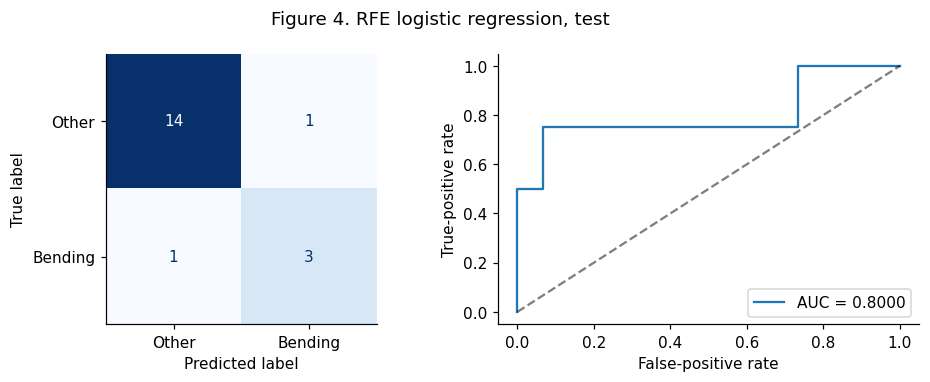

,accuracy,balanced_accuracy,auc
model,,,
RFE test,0.89474,0.84167,0.80000


selected_l          3.00000
selected_p          3.00000
mean_cv_accuracy    0.98571
test_accuracy       0.89474
test_minus_cv      -0.09098
dtype: float64

In [7]:
rfe_test_probability = rfe_model.predict_proba(Z_test)[:, 1]
rfe_test_metrics = binary_report("RFE test", y_test, rfe_test_probability,
                                "Figure 4. RFE logistic regression, test")
display(pd.Series({"selected_l": best_l, "selected_p": best_p,
                   "mean_cv_accuracy": rfe_best.cv_accuracy,
                   "test_accuracy": rfe_test_metrics["accuracy"],
                   "test_minus_cv": rfe_test_metrics["accuracy"] - rfe_best.cv_accuracy}))

## 2(a)(vi). Separation and numerical stability

The selected three-feature model is **not completely separable**: it makes one
training error, and the linear program is infeasible. Its coefficient norm
stabilizes near 7.036 as C increases from one million to one hundred million.
Thus this fitted subset does not show diverging coefficients, although richer
feature sets may separate the small training sample. The reported exploratory
Wald p-values are all above 0.05; individual conditional significance need not
track joint predictive accuracy, particularly after feature selection.

The linear-programming diagnostic above checks whether a hyperplane can
strictly separate every training label. Feasibility establishes complete
separation. For such data, coefficients can keep growing while the likelihood
improves, even when predictions have stabilized. The large-$C$ fit provides
finite numerical coefficients, but these are not a finite unpenalized MLE.

In [8]:
stability_rows = []
for C in [1e2, 1e4, 1e6, 1e8]:
    model = fit_model(logistic(C=C), selected_train, y_train)
    stability_rows.append({"C": C, "coefficient_L2_norm": np.linalg.norm(model.coef_),
                            "training_accuracy": model.score(selected_train, y_train),
                            "max_iterations_used": int(model.n_iter_.max())})
display(pd.DataFrame(stability_rows))

,C,coefficient_L2_norm,training_accuracy,max_iterations_used
0,100.00000,5.08539,0.98551,9
1,10000.00000,6.93148,0.98551,11
2,1000000.00000,7.03455,0.98551,11
3,100000000.00000,7.03566,0.98551,11


## 2(a)(vii). Class imbalance and case-control sampling

There are 9 bending recordings and 60 other recordings in training. An
always-other classifier already has accuracy $60/69=86.96\%$, so sensitivity
and the confusion matrix matter in addition to accuracy.

All 9 bending recordings and a random sample of 9 other training recordings
form a balanced case-control sample. Sampling uses seed 42. The same selected
features are refitted on this sample, and the intercept is corrected to the
original training prevalence:

$$\beta_{0,\mathrm{corrected}}=\beta_{0,\mathrm{sample}}
+\log\frac{\pi}{1-\pi}-\log\frac{\pi_s}{1-\pi_s},
\quad \pi=9/69,\quad\pi_s=1/2.$$

The adjustment changes probability calibration and classifications at 0.5,
but not the ordering of scores or AUC. It is the usual case-control correction;
with a small sample and a nearly unpenalized numerical fit its finite-sample
calibration remains approximate. The test prevalence is not used.

,sample_coefficient,corrected_coefficient
term,,
Intercept,-12.49451,-14.39163
max_s5_part1,15.10687,15.10687
min_s5_part3,8.46938,8.46938
std_s6_part3,-7.67073,-7.67073


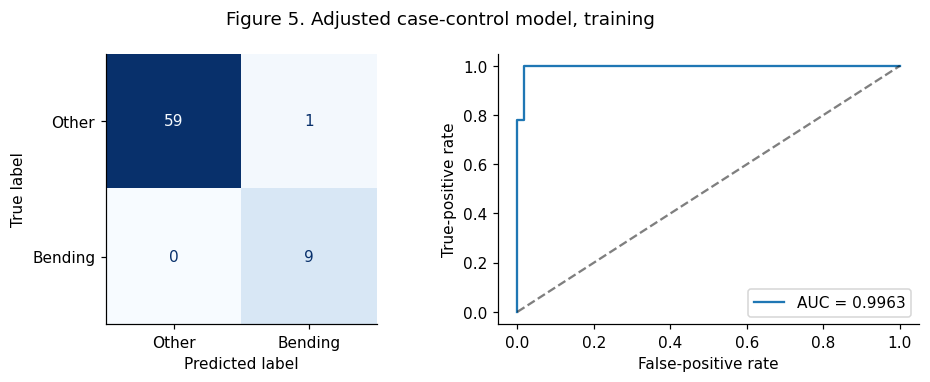

,accuracy,balanced_accuracy,auc
model,,,
Case-control train,0.98551,0.99167,0.99630


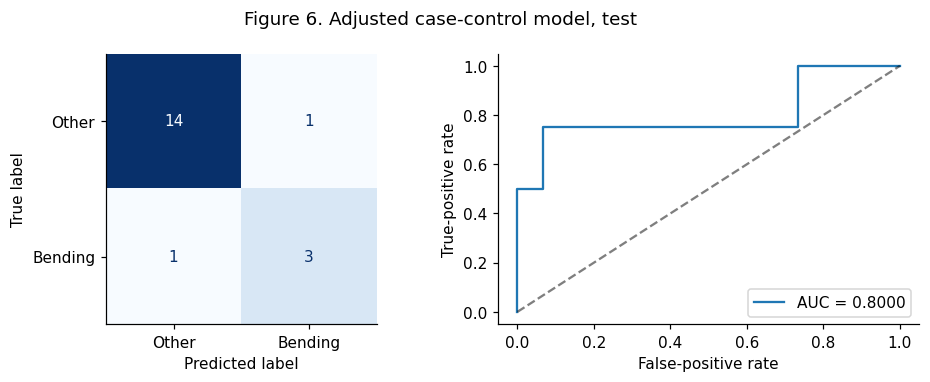

,accuracy,balanced_accuracy,auc
model,,,
Case-control test,0.89474,0.84167,0.80000


In [9]:
rng = np.random.default_rng(42)
case_indices = np.flatnonzero(y_train == 1)
control_indices = rng.choice(np.flatnonzero(y_train == 0), len(case_indices), replace=False)
case_control_indices = np.r_[case_indices, control_indices]
case_control = fit_model(logistic(), selected_train[case_control_indices], y_train[case_control_indices])
pi, pi_sample = y_train.mean(), y_train[case_control_indices].mean()
intercept_adjustment = np.log(pi/(1-pi)) - np.log(pi_sample/(1-pi_sample))
case_control_table = pd.DataFrame({"sample_coefficient": np.r_[case_control.intercept_[0], case_control.coef_[0]],
    "corrected_coefficient": np.r_[case_control.intercept_[0] + intercept_adjustment, case_control.coef_[0]]},
    index=pd.Index(["Intercept"] + chosen, name="term"))
display(case_control_table)
case_control_table.to_csv(results_dir / "case_control_coefficients.csv")
cc_train = expit(case_control.decision_function(selected_train) + intercept_adjustment)
cc_test = expit(case_control.decision_function(Z_test[:, rfe_model.support_]) + intercept_adjustment)
binary_report("Case-control train", y_train, cc_train, "Figure 5. Adjusted case-control model, training")
binary_report("Case-control test", y_test, cc_test, "Figure 6. Adjusted case-control model, test")
assert np.isclose(roc_auc_score(y_train, cc_train),
                  roc_auc_score(y_train, case_control.predict_proba(selected_train)[:, 1]))

## 2(b)(i). L1-penalized binary logistic regression

The search considers all 20 segmentation levels and
$C\in\{0.001,0.01,0.1,1,10,100,1000\}$, using the same five binary folds.
Standardization is fitted within each fold. LIBLINEAR fits the L1 models;
smaller $C$ means a stronger penalty. Ties favor smaller $C$, then smaller $l$.

,l,C,cv_accuracy,fold_1,fold_2,fold_3,fold_4,fold_5
129,19,1.00000,0.98571,1.00000,0.92857,1.00000,1.00000,1.00000
73,11,1.00000,0.97143,1.00000,0.92857,1.00000,0.92857,1.00000
80,12,1.00000,0.97143,1.00000,0.92857,1.00000,0.92857,1.00000
87,13,1.00000,0.97143,1.00000,0.92857,0.92857,1.00000,1.00000
94,14,1.00000,0.97143,1.00000,0.92857,0.92857,1.00000,1.00000
122,18,1.00000,0.97143,1.00000,0.92857,1.00000,0.92857,1.00000
136,20,1.00000,0.97143,1.00000,0.92857,1.00000,0.92857,1.00000
81,12,10.00000,0.97143,1.00000,0.92857,1.00000,0.92857,1.00000
123,18,10.00000,0.97143,1.00000,0.92857,1.00000,0.92857,1.00000
130,19,10.00000,0.97143,1.00000,0.92857,1.00000,0.92857,1.00000


,feature,coefficient
0,min_s5_part2,0.02213
1,q1_s5_part3,2.19407
2,max_s5_part5,0.01035
3,max_s1_part11,-0.57535
4,std_s4_part14,-0.04649
5,std_s6_part15,-0.20691
6,min_s5_part17,0.62194
7,std_s5_part18,-0.06204
8,max_s6_part18,-0.14138


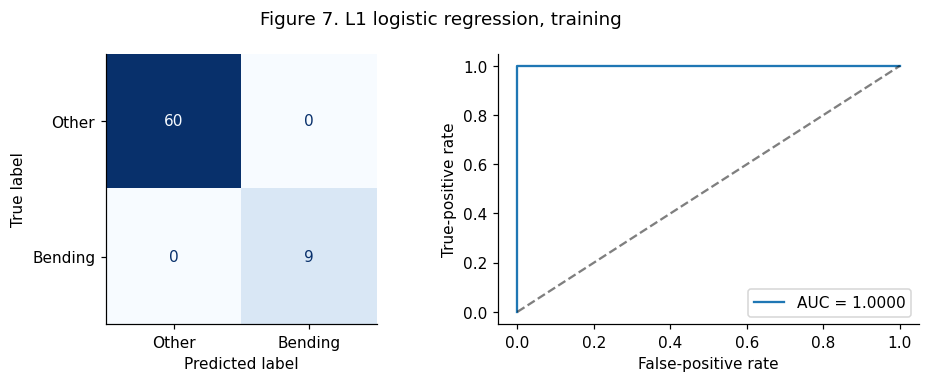

,accuracy,balanced_accuracy,auc
model,,,
L1 train,1.00000,1.00000,1.00000


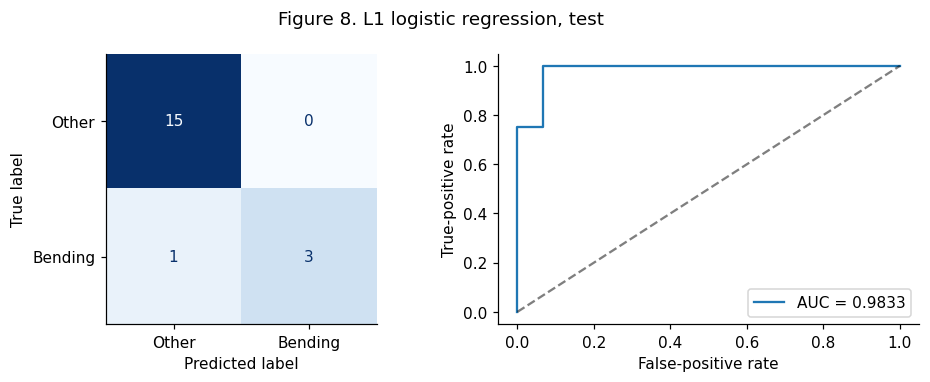

,accuracy,balanced_accuracy,auc
model,,,
L1 test,0.94737,0.87500,0.98333


In [10]:
binary_C = np.logspace(-3, 3, 7)
l1_rows = []
for l in range(1, 21):
    X = features[l].to_numpy()[train_mask]
    scores = {C: [] for C in binary_C}
    for fold_train, fold_valid in binary_folds:
        scaler = StandardScaler().fit(X[fold_train])
        Xt, Xv = scaler.transform(X[fold_train]), scaler.transform(X[fold_valid])
        for C in binary_C:
            model = fit_model(logistic(C, penalty="l1"), Xt, y_train[fold_train])
            scores[C].append(model.score(Xv, y_train[fold_valid]))
    for C, fold_scores in scores.items():
        l1_rows.append({"l": l, "C": C, "cv_accuracy": np.mean(fold_scores),
                        **{f"fold_{i+1}": score for i, score in enumerate(fold_scores)}})
l1_cv = pd.DataFrame(l1_rows)
l1_best = l1_cv.sort_values(["cv_accuracy", "C", "l"], ascending=[False, True, True]).iloc[0]
l1_l, l1_C = int(l1_best.l), float(l1_best.C)
display(l1_cv.sort_values(["cv_accuracy", "C", "l"], ascending=[False, True, True]).head(15))
l1_cv.to_csv(results_dir / "binary_l1_cv.csv", index=False)
X = features[l1_l].to_numpy()
l1_scaler = StandardScaler().fit(X[train_mask])
l1_train, l1_test = l1_scaler.transform(X[train_mask]), l1_scaler.transform(X[test_mask])
l1_model = fit_model(logistic(l1_C, penalty="l1"), l1_train, y_train)
nonzero = np.abs(l1_model.coef_[0]) > 1e-8
display(pd.DataFrame({"feature": features[l1_l].columns[nonzero], "coefficient": l1_model.coef_[0, nonzero]}))
l1_train_probability = l1_model.predict_proba(l1_train)[:, 1]
l1_test_probability = l1_model.predict_proba(l1_test)[:, 1]
l1_train_metrics = binary_report("L1 train", y_train, l1_train_probability,
                                "Figure 7. L1 logistic regression, training")
l1_test_metrics = binary_report("L1 test", y_test, l1_test_probability,
                               "Figure 8. L1 logistic regression, test")

## 2(b)(ii). Comparison with recursive feature elimination

L1 selects **l = 19, C = 1**, with **9 nonzero coefficients**. Both methods
have mean validation accuracy **98.57%**. L1 achieves higher observed test
accuracy (**94.74%**, versus **89.47%** for RFE), with one missed bending
recording and no false bending predictions. The equal validation scores do
not establish a predictive advantage for either family.

The table compares the permitted RFE approach with L1 selection. The CV score
determines model choice; test results describe the held-out comparison.
L1 is easier to implement because one penalty both shrinks coefficients and
sets some to zero. RFE needs a separate elimination loop and search over
the retained feature count. Ordinary p-value selection is especially problematic
under separation, whereas finite L1 estimates remain available.

In [11]:
binary_comparison = pd.DataFrame([
    {"method": "RFE", "l": best_l, "p_nonzero": best_p, "C": 1e6,
     "cv_accuracy": rfe_best.cv_accuracy, "test_accuracy": rfe_test_metrics["accuracy"]},
    {"method": "L1", "l": l1_l, "p_nonzero": int(nonzero.sum()), "C": l1_C,
     "cv_accuracy": l1_best.cv_accuracy, "test_accuracy": l1_test_metrics["accuracy"]}
])
display(binary_comparison)
binary_comparison.to_csv(results_dir / "binary_comparison.csv", index=False)
pd.DataFrame(binary_metrics).to_csv(results_dir / "binary_metrics.csv", index=False)

,method,l,p_nonzero,C,cv_accuracy,test_accuracy
0,RFE,3,3,1000000.00000,0.98571,0.89474
1,L1,19,9,1.00000,0.98571,0.94737


## 2(c)(i). L1 multinomial logistic regression

Seven activity folders are seven classes. Bending2 has only four training
recordings, so four stratified folds are used: five folds could not place
every class in every validation fold. All methods in this multiclass comparison
use the same four folds. The search considers $l=1,\ldots,20$ and
$C\in\{0.01,0.1,1,10\}$. Standardization is fitted within folds.
SAGA optimizes the joint multinomial likelihood with an L1 penalty, rather
than fitting seven unrelated binary models. Ties favor smaller $C$, then $l$.

In [12]:
multi_C = [.01, .1, 1., 10.]
multi_rows = []
for l in range(1, 21):
    X = features[l].to_numpy()[train_mask]
    scores = {C: [] for C in multi_C}
    for fold_train, fold_valid in multiclass_folds:
        scaler = StandardScaler().fit(X[fold_train])
        Xt, Xv = scaler.transform(X[fold_train]), scaler.transform(X[fold_valid])
        model = LogisticRegression(penalty="l1", solver="saga", multi_class="multinomial",
                                   warm_start=True, max_iter=15000, tol=1e-3, random_state=42)
        for C in multi_C:
            model.set_params(C=C)
            fit_model(model, Xt, ym_train[fold_train])
            scores[C].append(model.score(Xv, ym_train[fold_valid]))
    for C, fold_scores in scores.items():
        multi_rows.append({"l": l, "C": C, "cv_accuracy": np.mean(fold_scores),
                           **{f"fold_{i+1}": score for i, score in enumerate(fold_scores)}})
multi_cv = pd.DataFrame(multi_rows)
multi_best = multi_cv.sort_values(["cv_accuracy", "C", "l"], ascending=[False, True, True]).iloc[0]
multi_l = int(multi_best.l)
display(multi_cv.sort_values(["cv_accuracy", "C", "l"], ascending=[False, True, True]).head(15))
multi_cv.to_csv(results_dir / "multinomial_logistic_cv.csv", index=False)
X = features[multi_l].to_numpy()
multi_scaler = StandardScaler().fit(X[train_mask])
multi_train, multi_test = multi_scaler.transform(X[train_mask]), multi_scaler.transform(X[test_mask])
multi_model = fit_model(LogisticRegression(C=float(multi_best.C), penalty="l1", solver="saga",
    multi_class="multinomial", max_iter=15000, tol=1e-3, random_state=42), multi_train, ym_train)

,l,C,cv_accuracy,fold_1,fold_2,fold_3,fold_4
2,1,1.00000,0.91422,0.83333,0.88235,0.94118,1.00000
3,1,10.00000,0.88399,0.88889,0.76471,0.88235,1.00000
35,9,10.00000,0.87010,0.83333,0.76471,0.94118,0.94118
6,2,1.00000,0.87010,0.83333,0.94118,0.82353,0.88235
79,20,10.00000,0.86928,0.88889,0.82353,0.82353,0.94118
19,5,10.00000,0.85458,0.88889,0.70588,0.88235,0.94118
7,2,10.00000,0.85376,0.94444,0.76471,0.82353,0.88235
34,9,1.00000,0.84069,0.83333,0.70588,0.88235,0.94118
66,17,1.00000,0.84069,0.83333,0.76471,0.82353,0.94118
23,6,10.00000,0.83987,0.88889,0.70588,0.82353,0.94118


A multiclass confusion matrix has true classes in rows and predictions in
columns. Each ROC curve treats one activity as positive and the remaining
activities as negative, using that activity's predicted probability. Macro AUC
is the unweighted mean of the seven class AUCs; micro AUC pools the one-vs-rest
indicator entries. The following plots use the held-out test recordings.

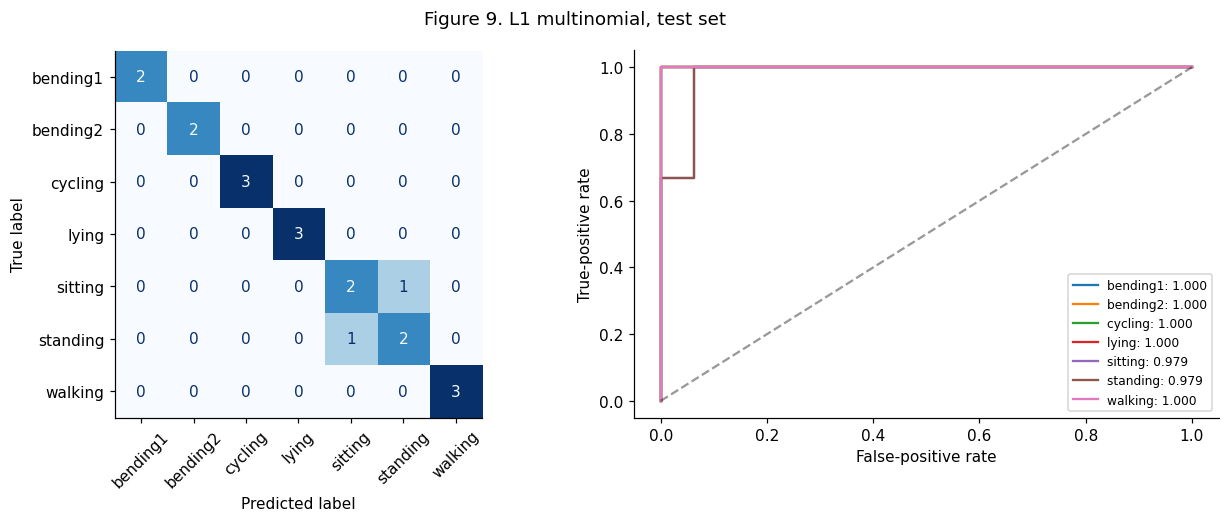

,cv_accuracy,test_accuracy,test_error,macro_ovr_auc,micro_ovr_auc
method,,,,,
L1 multinomial,0.91422,0.89474,0.10526,0.99405,0.99769


In [13]:
multiclass_metrics = []
def multiclass_report(name, model, Xtest, cv_accuracy, figure_number):
    probability = model.predict_proba(Xtest)
    classes = model.classes_
    predicted = classes[np.argmax(probability, axis=1)]
    truth = label_binarize(ym_test, classes=classes)
    row = {"method": name, "cv_accuracy": cv_accuracy,
           "test_accuracy": accuracy_score(ym_test, predicted),
           "test_error": 1-accuracy_score(ym_test, predicted),
           "macro_ovr_auc": roc_auc_score(truth, probability, average="macro"),
           "micro_ovr_auc": roc_auc_score(truth, probability, average="micro")}
    multiclass_metrics.append(row)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
    ConfusionMatrixDisplay.from_predictions(ym_test, predicted, labels=classes,
        ax=axes[0], xticks_rotation=45, colorbar=False, cmap="Blues")
    class_aucs = []
    for j, activity in enumerate(classes):
        fpr, tpr, _ = roc_curve(truth[:, j], probability[:, j])
        area = auc(fpr, tpr)
        class_aucs.append({"method": name, "class": activity, "auc": area})
        axes[1].plot(fpr, tpr, label=f"{activity}: {area:.3f}")
    axes[1].plot([0, 1], [0, 1], "k--", alpha=.4)
    axes[1].set(xlabel="False-positive rate", ylabel="True-positive rate")
    axes[1].legend(fontsize=8, loc="lower right")
    fig.suptitle(f"Figure {figure_number}. {name}, test set")
    fig.tight_layout()
    plt.show()
    display(pd.DataFrame([row]).set_index("method"))
    pd.DataFrame(probability, index=manifest.index[test_mask], columns=classes).to_csv(
        results_dir / (name.lower().replace(" ", "_") + "_test_probabilities.csv"))
    return class_aucs

class_auc_rows = multiclass_report("L1 multinomial", multi_model, multi_test,
                                  multi_best.cv_accuracy, 9)

## 2(c)(ii). Gaussian and multinomial naive Bayes

These methods use different **conditional feature distributions**, with
empirical training class priors in both cases. Gaussian naive Bayes models
each feature by a class-specific normal distribution. Multinomial naive Bayes
models nonnegative feature contributions and is conventionally intended for
counts. The extracted statistics are continuous, so its use here is an
approximation requested for comparison.

Gaussian smoothing is selected from $10^{-9},10^{-7},10^{-5},10^{-3}$.
Multinomial additive smoothing is selected from $0.01,0.1,1,10$.
The latter uses MaxAbs scaling fitted within folds, which keeps these
nonnegative statistics nonnegative without using validation extrema. All 20
segmentation levels are searched for both methods. Ties favor smaller $l$,
then the smaller smoothing parameter.

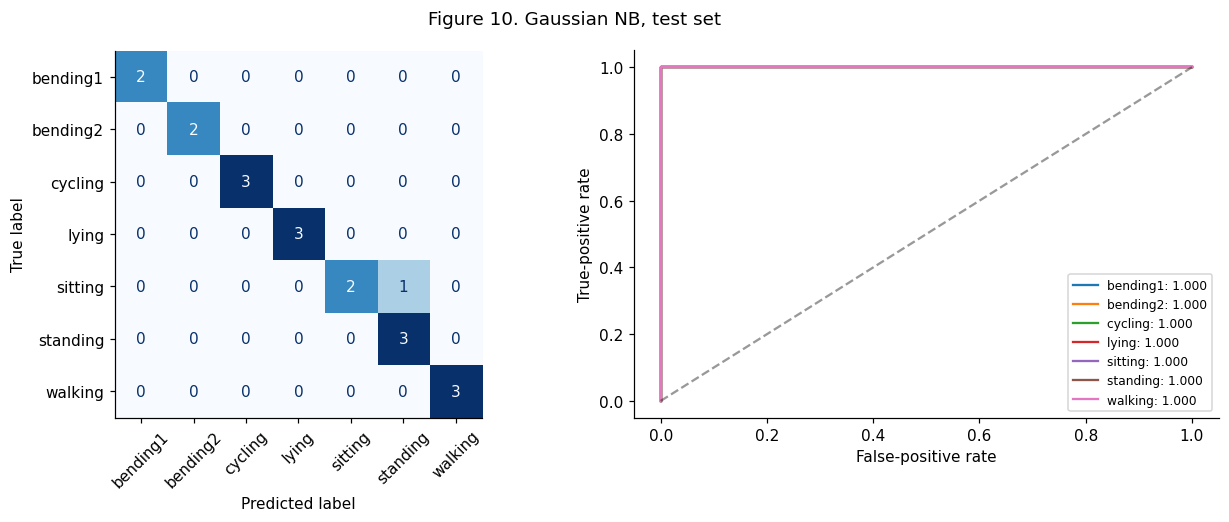

,cv_accuracy,test_accuracy,test_error,macro_ovr_auc,micro_ovr_auc
method,,,,,
Gaussian NB,0.89869,0.94737,0.05263,1.00000,0.99954


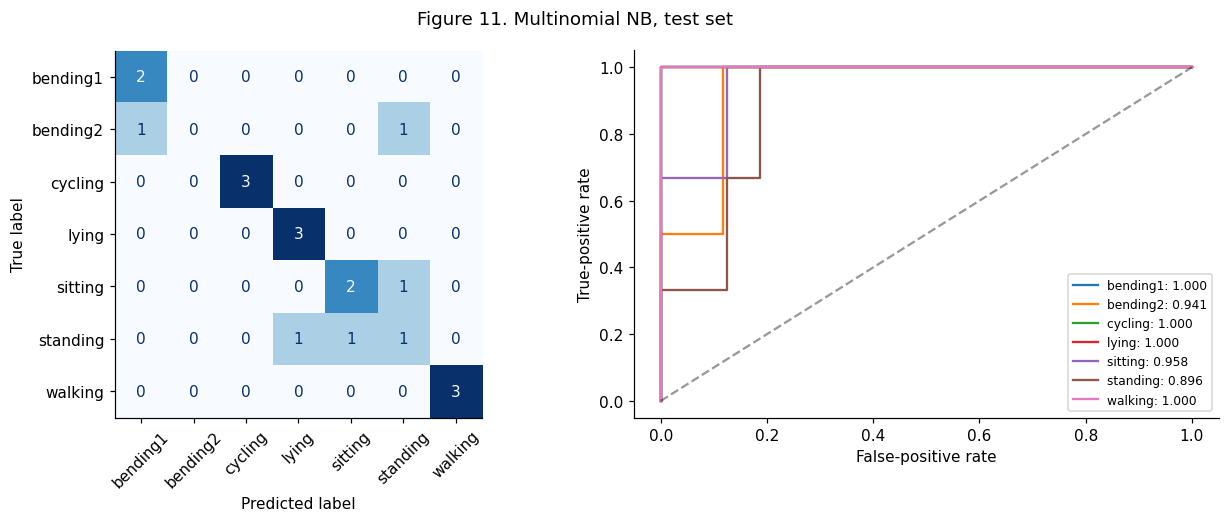

,cv_accuracy,test_accuracy,test_error,macro_ovr_auc,micro_ovr_auc
method,,,,,
Multinomial NB,0.82680,0.73684,0.26316,0.97076,0.97415


,method,l,smoothing,cv_accuracy
7,Gaussian NB,2,0.00100,0.89869
117,Multinomial NB,10,0.10000,0.82680


In [14]:
nb_rows = []
for method, parameters in [("Gaussian NB", [1e-9, 1e-7, 1e-5, 1e-3]),
                            ("Multinomial NB", [.01, .1, 1., 10.])]:
    for l in range(1, 21):
        X = features[l].to_numpy()[train_mask]
        scores = {parameter: [] for parameter in parameters}
        for fold_train, fold_valid in multiclass_folds:
            if method == "Multinomial NB":
                scaler = MaxAbsScaler().fit(X[fold_train])
                Xt, Xv = scaler.transform(X[fold_train]), scaler.transform(X[fold_valid])
            else:
                Xt, Xv = X[fold_train], X[fold_valid]
            for parameter in parameters:
                model = (GaussianNB(var_smoothing=parameter) if method == "Gaussian NB"
                         else MultinomialNB(alpha=parameter))
                fit_model(model, Xt, ym_train[fold_train])
                scores[parameter].append(model.score(Xv, ym_train[fold_valid]))
        for parameter, fold_scores in scores.items():
            nb_rows.append({"method": method, "l": l, "smoothing": parameter,
                            "cv_accuracy": np.mean(fold_scores),
                            **{f"fold_{i+1}": score for i, score in enumerate(fold_scores)}})
nb_cv = pd.DataFrame(nb_rows)
nb_cv.to_csv(results_dir / "naive_bayes_cv.csv", index=False)
nb_models = {}
nb_best_rows = []
for figure_number, method in enumerate(["Gaussian NB", "Multinomial NB"], start=10):
    best = nb_cv.loc[nb_cv.method.eq(method)].sort_values(
        ["cv_accuracy", "l", "smoothing"], ascending=[False, True, True]).iloc[0]
    nb_best_rows.append(best)
    l, parameter = int(best.l), float(best.smoothing)
    X = features[l].to_numpy()
    if method == "Multinomial NB":
        scaler = MaxAbsScaler().fit(X[train_mask])
        Xt, Xv = scaler.transform(X[train_mask]), scaler.transform(X[test_mask])
        model = MultinomialNB(alpha=parameter)
    else:
        Xt, Xv = X[train_mask], X[test_mask]
        model = GaussianNB(var_smoothing=parameter)
    fit_model(model, Xt, ym_train)
    nb_models[method] = (model, Xv, l, parameter)
    class_auc_rows.extend(multiclass_report(method, model, Xv, best.cv_accuracy, figure_number))
display(pd.DataFrame(nb_best_rows)[["method", "l", "smoothing", "cv_accuracy"]])

## 2(c)(iii). Multiclass comparison

L1 multinomial regression selects **l = 1, C = 1** and has the best mean
validation accuracy (**91.42%**). Gaussian naive Bayes selects **l = 2** and
variance smoothing **0.001**, with validation accuracy **89.87%**. Multinomial
naive Bayes selects **l = 10** and additive smoothing **0.1**, with validation
accuracy **82.68%**.

On the test recordings, **Gaussian naive Bayes performs best**, with error
**5.26% (1/19)**, compared with **10.53% (2/19)** for L1 multinomial regression
and **26.32% (5/19)** for multinomial naive Bayes. L1 multinomial regression is
the choice based on cross-validation; Gaussian naive Bayes is the strongest
observed test result. The Gaussian feature assumption is more natural for
these continuous summaries than the multinomial count model.

The comparison below reports the best tested configurations for each family.
The preferred model is selected by training cross-validation. The model with
the smallest observed test error is also identified, without retuning to that
test outcome. With only 19 test recordings, one error changes accuracy by
about 5.26 percentage points.

In [15]:
multiclass_comparison = pd.DataFrame(multiclass_metrics)
display(multiclass_comparison.sort_values("cv_accuracy", ascending=False))
display(pd.Series({"preferred_by_cv": multiclass_comparison.loc[multiclass_comparison.cv_accuracy.idxmax(), "method"],
                   "lowest_test_error": multiclass_comparison.loc[multiclass_comparison.test_error.eq(multiclass_comparison.test_error.min()), "method"].tolist(),
                   "convergence_warnings": len(fit_warnings)}))
multiclass_comparison.to_csv(results_dir / "multiclass_comparison.csv", index=False)
pd.DataFrame(class_auc_rows).to_csv(results_dir / "multiclass_auc.csv", index=False)
binary_predictions = pd.DataFrame({"actual": y_test, "rfe_probability": rfe_test_probability,
    "l1_probability": l1_test_probability, "case_control_probability": cc_test},
    index=manifest.index[test_mask])
binary_predictions.to_csv(results_dir / "binary_test_probabilities.csv")
summary = {"rfe_l": best_l, "rfe_p": best_p, "rfe_cv": float(rfe_best.cv_accuracy),
           "complete_separation": bool(separation), "l1_l": l1_l, "l1_C": l1_C,
           "l1_cv": float(l1_best.cv_accuracy), "l1_nonzero": int(nonzero.sum()),
           "multi_l": multi_l, "multi_C": float(multi_best.C),
           "fit_convergence_warnings": len(fit_warnings)}
(results_dir / "selected_models.json").write_text(json.dumps(summary, indent=2) + "\n")

,method,cv_accuracy,test_accuracy,test_error,macro_ovr_auc,micro_ovr_auc
0,L1 multinomial,0.91422,0.89474,0.10526,0.99405,0.99769
1,Gaussian NB,0.89869,0.94737,0.05263,1.00000,0.99954
2,Multinomial NB,0.82680,0.73684,0.26316,0.97076,0.97415


preferred_by_cv         L1 multinomial
lowest_test_error        [Gaussian NB]
convergence_warnings                 0
dtype: object

241

## 3. ISLR 4.8.3: Why QDA has quadratic discriminants

For one predictor, suppose $X\mid Y=k\sim N(\mu_k,\sigma_k^2)$
and let $\pi_k=P(Y=k)$. Bayes' rule assigns $x$ to the class maximizing
$\pi_k f_k(x)$. Taking logs and removing the constant
$-\tfrac12\log(2\pi)$ gives

$$\delta_k(x)=\log\pi_k-\frac12\log\sigma_k^2
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.$$

Expanding the square,

$$\delta_k(x)=-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}
-\frac12\log\sigma_k^2+\log\pi_k.$$

For classes $k$ and $j$, their boundary satisfies $\delta_k(x)-\delta_j(x)=0$:

$$\left(\frac{1}{2\sigma_j^2}-\frac{1}{2\sigma_k^2}\right)x^2
+\left(\frac{\mu_k}{\sigma_k^2}-\frac{\mu_j}{\sigma_j^2}\right)x
+\log\frac{\pi_k}{\pi_j}
-\frac12\log\frac{\sigma_k^2}{\sigma_j^2}
-\frac{\mu_k^2}{2\sigma_k^2}+\frac{\mu_j^2}{2\sigma_j^2}=0.$$

The $x^2$ coefficient generally does not cancel when class variances differ,
so the discriminant comparison is quadratic. In one dimension a pair of
classes can therefore have up to two boundary points. If the variances are
equal, the quadratic terms cancel and the comparison reduces to the linear
LDA form. Thus QDA is generally quadratic, with a linear special case.

## 4. ISLR 4.8.7: Probability of a dividend

The prior probabilities are $P(D)=0.8$ and $P(N)=0.2$. Conditional profit
distributions have means 10 and 0, respectively, and common variance 36.
For observed profit $X=4$, Bayes' rule gives

$$P(D\mid X=4)=\frac{0.8f_D(4)}{0.8f_D(4)+0.2f_N(4)}.$$

The common normalizing factor cancels. The density ratio is

$$\frac{f_N(4)}{f_D(4)}
=\exp\left(\frac{(4-10)^2-(4-0)^2}{72}\right)
=\exp(20/72).$$

Therefore,

$$P(D\mid X=4)=\frac{1}{1+(0.2/0.8)\exp(20/72)}
\approx 0.75185.$$

The estimated probability is **75.19%**, so the predicted class at a 0.5
threshold is **dividend = Yes**.

In [16]:
dividend_density = norm.pdf(4, loc=10, scale=6)
no_dividend_density = norm.pdf(4, loc=0, scale=6)
posterior = .8*dividend_density/(.8*dividend_density + .2*no_dividend_density)
display(pd.Series({"P(dividend | profit=4)": posterior,
                   "P(no dividend | profit=4)": 1-posterior}))

P(dividend | profit=4)      0.75185
P(no dividend | profit=4)   0.24815
dtype: float64

## References

1. Palumbo, F., Gallicchio, C., Pucci, R., and Micheli, A. (2016).
   [AReM dataset](https://doi.org/10.24432/C5SS33). UCI Machine Learning Repository, CC BY 4.0.
2. James, G., Witten, D., Hastie, T., and Tibshirani, R. (2021).
   *An Introduction to Statistical Learning*, second edition, Section 4.8,
   exercises 3 and 7, pp. 189-191. [Author's textbook site](https://www.statlearning.com/).
3. scikit-learn 1.5 documentation:
   [RFE](https://scikit-learn.org/1.5/modules/generated/sklearn.feature_selection.RFE.html),
   [logistic regression](https://scikit-learn.org/1.5/modules/generated/sklearn.linear_model.LogisticRegression.html),
   [stratified folds](https://scikit-learn.org/1.5/modules/generated/sklearn.model_selection.StratifiedKFold.html),
   [naive Bayes](https://scikit-learn.org/1.5/modules/naive_bayes.html),
   [ROC AUC](https://scikit-learn.org/1.5/modules/generated/sklearn.metrics.roc_auc_score.html).
4. SciPy documentation: [linear programming](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.linprog.html).